In [1]:
pwd

'D:\\gb_NLP_to_paper\\gb_nlp_scripts\\gb_nlp_scripts'

In [12]:
#imports 
import os,time,scipy
import pandas as pd
import numpy as np
from scipy import stats
from sklearn_extra.cluster import KMedoids
from sklearn.cluster import KMeans
import matplotlib.pyplot as plt

### functions

In [176]:
def global_Z(d1,d2):
    # global mean
    gm=(np.sum(d1)+np.sum(d2))/(len(d1)+len(d2))
    print("global mean:",gm)
    # global variance
    gv=(np.sum((d2-gm)**2)+np.sum((d1-gm)**2))/((len(d1)+len(d2))-1)
    print("global variance:",gv)
    # global standard deviation
    gs=np.sqrt(gv)
    print("global std:",gs)
    # global Z score 
    z1=(d1-gm)/(gs)
    z2=(d2-gm)/(gs)
    return z1,z2

In [ ]:
# N Folders or n nodes

In [333]:
pwd

'D:\\gb_NLP_to_paper\\gb_nlp_scripts\\gb_nlp_scripts'

In [339]:
s1=pd.read_csv("D:/gb_NLP_to_paper/gb_nlp_scripts/gb_nlp_scripts/gb_distributed/test/five/maast1/maast1.csv")
s2=pd.read_csv("D:/gb_NLP_to_paper/gb_nlp_scripts/gb_nlp_scripts/gb_distributed/test/five/maast2/maast2.csv")
s3=pd.read_csv("D:/gb_NLP_to_paper/gb_nlp_scripts/gb_nlp_scripts/gb_distributed/test/five/maast3/maast3.csv")
s4=pd.read_csv("D:/gb_NLP_to_paper/gb_nlp_scripts/gb_nlp_scripts/gb_distributed/test/five/tmh1/tmh1.csv")
s5=pd.read_csv("D:/gb_NLP_to_paper/gb_nlp_scripts/gb_nlp_scripts/gb_distributed/test/five/tmh2/tmh2.csv")

In [348]:
from pathlib import Path
#creating a new directory called pythondirectory
Path("D:/gb_NLP_to_paper/gb_nlp_scripts/gb_nlp_scripts/gb_distributed/test/five_var/maast1").mkdir(parents=True, exist_ok=True)
Path("D:/gb_NLP_to_paper/gb_nlp_scripts/gb_nlp_scripts/gb_distributed/test/five_var/maast2").mkdir(parents=True, exist_ok=True)
Path("D:/gb_NLP_to_paper/gb_nlp_scripts/gb_nlp_scripts/gb_distributed/test/five_var/maast3").mkdir(parents=True, exist_ok=True)
Path("D:/gb_NLP_to_paper/gb_nlp_scripts/gb_nlp_scripts/gb_distributed/test/five_var/tmh1").mkdir(parents=True, exist_ok=True)
Path("D:/gb_NLP_to_paper/gb_nlp_scripts/gb_nlp_scripts/gb_distributed/test/five_var/tmh2").mkdir(parents=True, exist_ok=True)

In [349]:
s1.iloc[:,0:10].to_csv("D:/gb_NLP_to_paper/gb_nlp_scripts/gb_nlp_scripts/gb_distributed/test/five_var/maast1/m1.csv",index=False)
s2.iloc[:,1:11].to_csv("D:/gb_NLP_to_paper/gb_nlp_scripts/gb_nlp_scripts/gb_distributed/test/five_var/maast2/m2.csv",index=False)
s3.iloc[:,2:12].to_csv("D:/gb_NLP_to_paper/gb_nlp_scripts/gb_nlp_scripts/gb_distributed/test/five_var/maast3/m3.csv",index=False)
s4.iloc[:,3:13].to_csv("D:/gb_NLP_to_paper/gb_nlp_scripts/gb_nlp_scripts/gb_distributed/test/five_var/tmh1/t1.csv",index=False)
s5.iloc[:,4:14].to_csv("D:/gb_NLP_to_paper/gb_nlp_scripts/gb_nlp_scripts/gb_distributed/test/five_var/tmh2/t2.csv",index=False)

In [340]:
s2.iloc[:,1:11]

,wavelet-HLH_glcm_ClusterProminence,original_shape_Maximum3DDiameter,log-sigma-3-mm-3D_glcm_Idn,original_shape_MajorAxisLength,wavelet-LLH_gldm_SmallDependenceHighGrayLevelEmphasis,original_shape_Maximum2DDiameterRow,wavelet-HLH_glcm_DifferenceVariance,log-sigma-3-mm-3D_ngtdm_Contrast,wavelet-HLH_glrlm_GrayLevelVariance,wavelet-HLH_firstorder_Variance
0,136760.35590,40.693980,0.885170,33.533787,1351.132792,38.832976,76.494473,0.380864,83.750048,2044.815333
1,139865.20650,64.899923,0.887469,59.921928,3966.276698,54.405882,76.769673,0.491323,94.101733,2310.959755
2,323206.94260,133.401649,0.939131,103.710841,7545.397757,79.649231,114.161816,0.091066,102.737282,2434.106141
3,118984.84130,129.151074,0.970849,108.752045,8826.331951,103.942292,38.973060,0.022095,36.539050,805.355647
4,78651.29300,33.823069,0.899487,25.385403,3538.344761,23.409400,52.961895,0.317559,72.491147,1777.269623
...,...,...,...,...,...,...,...,...,...,...
195,208129.12240,59.363288,0.930926,46.044642,9062.714034,36.055513,90.131358,0.156071,107.940911,2628.203627
196,295704.39730,96.540147,0.947905,77.108424,1544.052890,96.519428,83.738456,0.101156,87.180319,2019.443859
197,132267.83350,82.607506,0.942093,67.003320,5028.553756,80.523289,69.809987,0.084423,75.723537,1791.780731
198,50134.27343,97.549987,0.968403,71.474756,1750.729053,82.462113,30.627458,0.027919,33.507058,760.767474


In [350]:
import os,time,scipy

#del(gb)
#path='D:/gb_NLP_to_paper/gb_nlp_scripts/gb_nlp_scripts/gb_distributed/data/' # original
#path='D:/gb_NLP_to_paper/gb_nlp_scripts/gb_nlp_scripts/gb_distributed/test/five/'
path='D:/gb_NLP_to_paper/gb_nlp_scripts/gb_nlp_scripts/gb_distributed/test/five_var/'
gb_main=[]
start=time.process_time()
for dirName, subdirList, fileList in os.walk(path): 
    print(subdirList)
    
    for f in fileList:
        if ".csv" in f: # read radiomics from individual nodes
            data=os.path.join(dirName, f)
            print(data)
            node0=pd.read_csv(data)
            #node1=node0[gb_108_ft_std_100] #100 stable features
            #node1=node0[g1]# 218 stable features
            #node1=node0# 108 stable RAW features
            gb_main.append(node0)

['maast1', 'maast2', 'maast3', 'tmh1', 'tmh2']
[]
D:/gb_NLP_to_paper/gb_nlp_scripts/gb_nlp_scripts/gb_distributed/test/five_var/maast1\m1.csv
[]
D:/gb_NLP_to_paper/gb_nlp_scripts/gb_nlp_scripts/gb_distributed/test/five_var/maast2\m2.csv
[]
D:/gb_NLP_to_paper/gb_nlp_scripts/gb_nlp_scripts/gb_distributed/test/five_var/maast3\m3.csv
[]
D:/gb_NLP_to_paper/gb_nlp_scripts/gb_nlp_scripts/gb_distributed/test/five_var/tmh1\t1.csv
[]
D:/gb_NLP_to_paper/gb_nlp_scripts/gb_nlp_scripts/gb_distributed/test/five_var/tmh2\t2.csv


In [351]:
len(gb_main)

5

In [101]:
type(gb_main)

list

In [201]:
len(gb)

5

In [202]:
np.sum(gb[2]['wavelet-HLH_glcm_ClusterProminence'])

14883988.841261

In [203]:
np.sum(gb_main[0].iloc[:,0])

6803.7663048800005

In [206]:
len(gb_main[2].iloc[:,0])

120

In [152]:
np.sum(gb_main[1].iloc[:,0])

12821.062315980002

In [155]:
len(gb_main[1].iloc[:,0])

200

In [146]:
np.sum(gb_main[1].iloc[:,0])

12821.062315980002

In [135]:
np.sum([np.sum(x) for x in gb])

210767332.6055464

In [195]:
for i in range(len(gb_main[0].columns)):
    #  irrespective of column order between the nodes
    if gb_main[0].columns[i] in gb_main[1].columns:
        s=list(gb_main[1].columns).index(str(gb_main[0].columns[i]))
        #print(s,i,'++++++++')
        r1,r2=global_Z(d1=gb_main[0].iloc[:,i],d2=gb_main[1].iloc[:,s])

global mean: 61.042644488133334
global variance: 962.9921946139217
global std: 31.032115535585415
global mean: 202566.15105667
global variance: 103778400434.70908
global std: 322146.551176183
global mean: 71.23353148403332
global variance: 1185.562534065908
global std: 34.43199869403326
global mean: 0.9316973609199999
global variance: 0.0010815031135320023
global std: 0.03288621464279527
global mean: 58.074778875566665
global variance: 843.445495236693
global std: 29.042133104107435
global mean: 4574.143202774
global variance: 11240949.564223705
global std: 3352.7525354883714
global mean: 62.91851112763333
global variance: 1029.1447734644116
global std: 32.08028636817963
global mean: 68.19239237755333
global variance: 2272.755670786845
global std: 47.67342730271073
global mean: 0.21433990688666668
global variance: 0.09424924484098648
global std: 0.30700039876356267
global mean: 79.72797945380667
global variance: 3896.9496009910563
global std: 62.42555246844882
global mean: 1913.7725767

global mean: 0.05528342712666666
global variance: 0.0006266464278977614
global std: 0.02503290690067299
global mean: 0.4159293002333333
global variance: 0.03782893645273507
global std: 0.19449662324250022
global mean: 32.276867566060005
global variance: 973.2455237752241
global std: 31.19688323815737
global mean: 873.3358248663333
global variance: 62673.70834336318
global std: 250.34717562489732
global mean: 897.4853999411334
global variance: 522299.41114915576
global std: 722.7028512114476
global mean: 0.0080155401
global variance: 5.281180706846879e-05
global std: 0.00726717325157924
global mean: 0.4228810347666666
global variance: 0.02168449019088386
global std: 0.14725654549419478
global mean: 13.05512740725
global variance: 84.78943003216202
global std: 9.208117616112537
global mean: 16.127664723936668
global variance: 91.64526156766755
global std: 9.573153167460946
global mean: 91.74406980363332
global variance: 2202.591987607239
global std: 46.93178014530494
global mean: 13.5030

In [304]:
list((set(p1.columns) & set(p2.columns) & set(p3.columns)))

['U', 'P']

In [329]:
r=[[1,10],[32,65]]
dr=[set(x) for x in r]
str(np.bitwise_and.reduce(dr))

'set()'

In [322]:
P=[p1.columns,p2.columns,p3.columns]
dp=[set(x) for x in P]
list(np.bitwise_and.reduce(dp))

['U', 'P']

In [305]:
list(dp[0] & dp[1] & dp[2])

['U', 'P']

In [353]:
gb=gb_main

In [379]:
ds=[set(x.columns) for x in gb]
su_common=list(np.bitwise_and.reduce(ds))
print('common features among all nodes: \n',su_common)

common features among all nodes: 
 ['wavelet-HLH_glcm_DifferenceVariance', 'wavelet-HLH_glrlm_GrayLevelVariance', 'log-sigma-3-mm-3D_ngtdm_Contrast', 'wavelet-LLH_gldm_SmallDependenceHighGrayLevelEmphasis', 'original_shape_Maximum2DDiameterRow', 'original_shape_MajorAxisLength']


In [365]:
s1.iloc[:,0:10].columns

Index(['original_shape_Maximum2DDiameterColumn',
       'wavelet-HLH_glcm_ClusterProminence',
       'original_shape_Maximum3DDiameter', 'log-sigma-3-mm-3D_glcm_Idn',
       'original_shape_MajorAxisLength',
       'wavelet-LLH_gldm_SmallDependenceHighGrayLevelEmphasis',
       'original_shape_Maximum2DDiameterRow',
       'wavelet-HLH_glcm_DifferenceVariance',
       'log-sigma-3-mm-3D_ngtdm_Contrast',
       'wavelet-HLH_glrlm_GrayLevelVariance'],
      dtype='object')

In [366]:
s2.iloc[:,1:11].columns

Index(['wavelet-HLH_glcm_ClusterProminence',
       'original_shape_Maximum3DDiameter', 'log-sigma-3-mm-3D_glcm_Idn',
       'original_shape_MajorAxisLength',
       'wavelet-LLH_gldm_SmallDependenceHighGrayLevelEmphasis',
       'original_shape_Maximum2DDiameterRow',
       'wavelet-HLH_glcm_DifferenceVariance',
       'log-sigma-3-mm-3D_ngtdm_Contrast',
       'wavelet-HLH_glrlm_GrayLevelVariance',
       'wavelet-HLH_firstorder_Variance'],
      dtype='object')

In [367]:
s3.iloc[:,2:12].columns

Index(['original_shape_Maximum3DDiameter', 'log-sigma-3-mm-3D_glcm_Idn',
       'original_shape_MajorAxisLength',
       'wavelet-LLH_gldm_SmallDependenceHighGrayLevelEmphasis',
       'original_shape_Maximum2DDiameterRow',
       'wavelet-HLH_glcm_DifferenceVariance',
       'log-sigma-3-mm-3D_ngtdm_Contrast',
       'wavelet-HLH_glrlm_GrayLevelVariance',
       'wavelet-HLH_firstorder_Variance',
       'log-sigma-3-mm-3D_gldm_DependenceNonUniformityNormalized'],
      dtype='object')

In [370]:
s4.iloc[:,3:13].columns

Index(['log-sigma-3-mm-3D_glcm_Idn', 'original_shape_MajorAxisLength',
       'wavelet-LLH_gldm_SmallDependenceHighGrayLevelEmphasis',
       'original_shape_Maximum2DDiameterRow',
       'wavelet-HLH_glcm_DifferenceVariance',
       'log-sigma-3-mm-3D_ngtdm_Contrast',
       'wavelet-HLH_glrlm_GrayLevelVariance',
       'wavelet-HLH_firstorder_Variance',
       'log-sigma-3-mm-3D_gldm_DependenceNonUniformityNormalized',
       'wavelet-HLH_gldm_GrayLevelVariance'],
      dtype='object')

In [371]:
s5.iloc[:,4:14].columns

Index(['original_shape_MajorAxisLength',
       'wavelet-LLH_gldm_SmallDependenceHighGrayLevelEmphasis',
       'original_shape_Maximum2DDiameterRow',
       'wavelet-HLH_glcm_DifferenceVariance',
       'log-sigma-3-mm-3D_ngtdm_Contrast',
       'wavelet-HLH_glrlm_GrayLevelVariance',
       'wavelet-HLH_firstorder_Variance',
       'log-sigma-3-mm-3D_gldm_DependenceNonUniformityNormalized',
       'wavelet-HLH_gldm_GrayLevelVariance', 'wavelet-HLL_ngtdm_Contrast'],
      dtype='object')

In [314]:
for i in range(len(ds)):
    f
    print(ds[i] & ds[i])

{'wavelet-HLL_firstorder_Variance', 'wavelet-HLH_glrlm_GrayLevelNonUniformityNormalized', 'original_gldm_DependenceVariance', 'wavelet-LLH_firstorder_RobustMeanAbsoluteDeviation', 'wavelet-HHH_glrlm_LongRunEmphasis', 'wavelet-HHH_glcm_MaximumProbability', 'log-sigma-3-mm-3D_firstorder_MeanAbsoluteDeviation', 'wavelet-LLH_gldm_DependenceNonUniformityNormalized', 'original_shape_MajorAxisLength', 'wavelet-HHL_ngtdm_Contrast', 'wavelet-HHH_glcm_SumEntropy', 'wavelet-HHH_gldm_GrayLevelVariance', 'wavelet-LLH_glcm_SumEntropy', 'wavelet-LHH_gldm_GrayLevelVariance', 'wavelet-HLH_gldm_LargeDependenceEmphasis', 'wavelet-HLH_firstorder_Entropy', 'wavelet-HHL_glcm_DifferenceVariance', 'wavelet-LLH_gldm_SmallDependenceEmphasis', 'wavelet-HLH_gldm_SmallDependenceHighGrayLevelEmphasis', 'wavelet-HLH_glcm_Contrast', 'wavelet-LHH_firstorder_InterquartileRange', 'wavelet-LLH_glcm_Idn', 'wavelet-HHL_gldm_DependenceNonUniformityNormalized', 'wavelet-HHH_glszm_ZonePercentage', 'wavelet-HHH_firstorder_Entr

In [306]:
list(ds[1] & ds[2] & ds[3])

['wavelet-HLL_firstorder_Variance',
 'wavelet-HLH_glrlm_GrayLevelNonUniformityNormalized',
 'original_gldm_DependenceVariance',
 'wavelet-LLH_firstorder_RobustMeanAbsoluteDeviation',
 'wavelet-HHH_glrlm_LongRunEmphasis',
 'wavelet-HHH_glcm_MaximumProbability',
 'log-sigma-3-mm-3D_firstorder_MeanAbsoluteDeviation',
 'wavelet-LLH_gldm_DependenceNonUniformityNormalized',
 'original_shape_MajorAxisLength',
 'wavelet-HHH_glcm_SumEntropy',
 'wavelet-HHL_ngtdm_Contrast',
 'wavelet-HHH_gldm_GrayLevelVariance',
 'wavelet-LHH_gldm_GrayLevelVariance',
 'wavelet-LLH_glcm_SumEntropy',
 'wavelet-HLH_gldm_LargeDependenceEmphasis',
 'wavelet-HLH_firstorder_Entropy',
 'wavelet-HHL_glcm_DifferenceVariance',
 'wavelet-LLH_gldm_SmallDependenceEmphasis',
 'wavelet-HLH_gldm_SmallDependenceHighGrayLevelEmphasis',
 'wavelet-HLH_glcm_Contrast',
 'wavelet-LHH_firstorder_InterquartileRange',
 'wavelet-LLH_glcm_Idn',
 'wavelet-HHL_gldm_DependenceNonUniformityNormalized',
 'wavelet-HHH_glszm_ZonePercentage',
 'wav

In [272]:

for i in ds:
    print(i)
    

SyntaxError: invalid syntax (<ipython-input-272-0215e83465de>, line 4)

In [237]:
list(set(gb[0].columns) & set(gb[1].columns) & set(gb[2].columns))

['wavelet-HLL_firstorder_Variance',
 'wavelet-HLH_glrlm_GrayLevelNonUniformityNormalized',
 'original_gldm_DependenceVariance',
 'wavelet-LLH_firstorder_RobustMeanAbsoluteDeviation',
 'wavelet-HHH_glrlm_LongRunEmphasis',
 'wavelet-HHH_glcm_MaximumProbability',
 'log-sigma-3-mm-3D_firstorder_MeanAbsoluteDeviation',
 'wavelet-LLH_gldm_DependenceNonUniformityNormalized',
 'original_shape_MajorAxisLength',
 'wavelet-HHH_glcm_SumEntropy',
 'wavelet-HHL_ngtdm_Contrast',
 'wavelet-HHH_gldm_GrayLevelVariance',
 'wavelet-LHH_gldm_GrayLevelVariance',
 'wavelet-LLH_glcm_SumEntropy',
 'wavelet-HLH_gldm_LargeDependenceEmphasis',
 'wavelet-HLH_firstorder_Entropy',
 'wavelet-HHL_glcm_DifferenceVariance',
 'wavelet-LLH_gldm_SmallDependenceEmphasis',
 'wavelet-HLH_gldm_SmallDependenceHighGrayLevelEmphasis',
 'wavelet-HLH_glcm_Contrast',
 'wavelet-LHH_firstorder_InterquartileRange',
 'wavelet-LLH_glcm_Idn',
 'wavelet-HHL_gldm_DependenceNonUniformityNormalized',
 'wavelet-HHH_glszm_ZonePercentage',
 'wav

In [235]:
gb[0].head(n=1)

,original_shape_Maximum2DDiameterColumn,wavelet-HLH_glcm_ClusterProminence,original_shape_Maximum3DDiameter,log-sigma-3-mm-3D_glcm_Idn,original_shape_MajorAxisLength,wavelet-LLH_gldm_SmallDependenceHighGrayLevelEmphasis,original_shape_Maximum2DDiameterRow,wavelet-HLH_glcm_DifferenceVariance,log-sigma-3-mm-3D_ngtdm_Contrast,wavelet-HLH_glrlm_GrayLevelVariance,...,wavelet-HLH_glszm_GrayLevelNonUniformityNormalized,wavelet-LHL_glrlm_RunPercentage,wavelet-LHL_gldm_LargeDependenceEmphasis,log-sigma-3-mm-3D_firstorder_MeanAbsoluteDeviation.1,wavelet-LHH_glrlm_GrayLevelVariance,wavelet-LLH_glcm_JointEnergy,wavelet-HHH_glcm_Contrast,wavelet-LHH_gldm_GrayLevelVariance,wavelet-HHH_glcm_SumSquares,wavelet-HHH_glcm_ClusterTendency
0,94.339811,102903.8051,95.833188,0.952934,84.562987,5392.57145,82.873397,57.002572,0.059098,60.747178,...,0.03068,0.971056,4.216829,65.158992,87.697174,0.002084,39.597502,83.438574,19.356675,37.829198


In [236]:
gb[1].head(n=1)

,original_shape_Maximum2DDiameterColumn,wavelet-HLH_glcm_ClusterProminence,original_shape_Maximum3DDiameter,log-sigma-3-mm-3D_glcm_Idn,original_shape_MajorAxisLength,wavelet-LLH_gldm_SmallDependenceHighGrayLevelEmphasis,original_shape_Maximum2DDiameterRow,wavelet-HLH_glcm_DifferenceVariance,log-sigma-3-mm-3D_ngtdm_Contrast,wavelet-HLH_glrlm_GrayLevelVariance,...,wavelet-HLH_glszm_GrayLevelNonUniformityNormalized,wavelet-LHL_glrlm_RunPercentage,wavelet-LHL_gldm_LargeDependenceEmphasis,log-sigma-3-mm-3D_firstorder_MeanAbsoluteDeviation.1,wavelet-LHH_glrlm_GrayLevelVariance,wavelet-LLH_glcm_JointEnergy,wavelet-HHH_glcm_Contrast,wavelet-LHH_gldm_GrayLevelVariance,wavelet-HHH_glcm_SumSquares,wavelet-HHH_glcm_ClusterTendency
0,34.985711,136760.3559,40.69398,0.88517,33.533787,1351.132792,38.832976,76.494473,0.380864,83.750048,...,0.029827,0.987864,2.085259,93.474901,57.694654,0.00109,64.002549,56.258551,31.067475,60.267352


In [219]:
# generalized global mean
gm=np.sum([np.sum(x.iloc[:,10]) for x in gb])/np.sum([len(x.iloc[:,10]) for x in gb])
gm

1497.5013794508288

In [220]:
# global variance
gv=(np.sum([np.sum((x.iloc[:,10]-gm)**2) for x in gb]))/(np.sum([len(x.iloc[:,10]) for x in gb])-1)
gv

1789521.8313416291

In [221]:
# global standard deviations
gs=np.sqrt(gv)
gs

1337.730104072428

In [222]:
# final global scalings 
[(x.iloc[:,1]-gm)/(gs) for x in gb]

[0      75.804756
 1      44.247279
 2     255.254214
 3      46.461090
 4     151.226341
          ...    
 95     11.404902
 96    308.551262
 97     98.503269
 98    411.555114
 99    112.101407
 Name: wavelet-HLH_glcm_ClusterProminence, Length: 100, dtype: float64,
 0      101.113711
 1      103.434695
 2      240.489050
 3       87.825892
 4       57.675155
           ...    
 195    154.464357
 196    219.929936
 197     97.755393
 198     36.357687
 199    204.522960
 Name: wavelet-HLH_glcm_ClusterProminence, Length: 200, dtype: float64,
 0      164.191806
 1       49.169850
 2       71.610122
 3      205.755558
 4      286.102232
           ...    
 115    616.701931
 116     69.709885
 117     33.752148
 118     62.641893
 119     80.757242
 Name: wavelet-HLH_glcm_ClusterProminence, Length: 120, dtype: float64,
 0      0.337041
 1     -0.923571
 2     61.600554
 3     -0.737509
 4     -0.808025
         ...    
 75     5.944296
 76    -0.976411
 77     0.289469
 78     7.84281

In [190]:
(gb_main[1].iloc[:,0]-gm)/(gs)

0      0.095285
1      1.241731
2      1.036530
3      0.950111
4     -0.969188
         ...   
195    0.884601
196   -0.003805
197    0.070242
198   -1.182590
199   -0.141493
Name: original_shape_Maximum2DDiameterColumn, Length: 200, dtype: float64

In [189]:
[(x.iloc[:,0]-gm)/(gs) for x in gb]

[0      1.002929
 1      1.641442
 2     -0.216698
 3      1.515035
 4      0.486621
          ...   
 415    1.283747
 416    0.288155
 417   -0.616651
 418   -0.168772
 419   -0.320377
 Name: original_shape_Maximum2DDiameterColumn, Length: 420, dtype: float64,
 0      0.095285
 1      1.241731
 2      1.036530
 3      0.950111
 4     -0.969188
          ...   
 195    0.884601
 196   -0.003805
 197    0.070242
 198   -1.182590
 199   -0.141493
 Name: original_shape_Maximum2DDiameterColumn, Length: 200, dtype: float64]

In [ ]:
[np.sum((x.iloc[:,0]-gm)**2) for x in gb]

In [185]:
gb_main[0].iloc[:,0]

0       94.339811
1      114.769334
2       55.317267
3      110.724884
4       77.820306
          ...    
415    103.324731
416     71.470274
417     42.520583
418     56.850682
419     52.000000
Name: original_shape_Maximum2DDiameterColumn, Length: 420, dtype: float64

In [182]:
94-62

32

In [ ]:
# generalized global mean
gm=np.sum([np.sum(x.iloc[:,1]) for x in gb])/np.sum([len(x.iloc[:,1]) for x in gb])

# generalized global variance 


    gm=(np.sum(d1)+np.sum(d2))/(len(d1)+len(d2))
    # global variance
    gv=(np.sum((d2-gm)**2)+np.sum((d1-gm)**2))/((len(d1)+len(d2))-1)
    # global standard deviation
    gs=np.sqrt(gv)
    # global Z score 
    z1=(d1-gm)/(gs)
    z2=(d2-gm)/(gs)
    return z1,z2

In [103]:
def global_Z(gb=[]):
    # global mean
    np.sum(x) for x in gb
    gm=(np.sum(d1)+np.sum(d2))/(len(d1)+len(d2))
    # global variance
    gv=(np.sum((d2-gm)**2)+np.sum((d1-gm)**2))/((len(d1)+len(d2))-1)
    # global standard deviation
    gs=np.sqrt(gv)
    # global Z score 
    z1=(d1-gm)/(gs)
    z2=(d2-gm)/(gs)
    return z1,z2

In [14]:
#
# function that returns
# Pearson correlation coefficient.
def correlationCoefficient_wt(X, Y):
    n = len(X)
    sum_X = 0
    sum_Y = 0
    sum_XY = 0
    squareSum_X = 0
    squareSum_Y = 0
 
    for i in range(n):
 
        # sum of elements of array X.
        sum_X = sum_X + X[i]
 
        # sum of elements of array Y.
        sum_Y = sum_Y + Y[i]
 
        # sum of X[i] * Y[i].
        sum_XY = sum_XY + X[i] * Y[i]
 
        # sum of square of array
        squareSum_X = squareSum_X + X[i] * X[i] # to reduce
        squareSum_Y = squareSum_Y + Y[i] * Y[i] # to reduce
 
    # use formula for calculating
    # correlation coefficient.
  # master node 
        corr = (n * sum_XY - sum_X * sum_Y) /((n * squareSum_X -sum_X * sum_X) * (n * squareSum_Y - sum_Y * sum_Y)) ** 0.5
 
    #print('observations:',n,'\n','sum_XY:',sum_XY,'\n','sum_X:',sum_X,'\n',
    #              'sum_Y:',sum_Y,'\n','Sum_square_X:',squareSum_X ,'\n','Sum_square_Y:',
    #              squareSum_Y,'\n' ,)
    #print(squareSum_X,'\t\t',squareSum_Y,'\t\t',sum_XY)
    return n,sum_XY,sum_X,sum_Y,squareSum_X,squareSum_Y
    #return corr

In [15]:
def Global_corr(n,sum_X,sum_Y, sum_XY,squareSum_X,squareSum_Y):
    corrr= (n * sum_XY - sum_X * sum_Y) /((n * squareSum_X -sum_X * sum_X) * (n * squareSum_Y - sum_Y * sum_Y)) ** 0.5
    return corrr

## Step 1

### # Global Zcore scaling

In [172]:
#*0
# Global Zcore scaling
#r1,r2=global_Z(d1=tmh_108_raw.iloc[:,1],d2=lung1_1093_raw.iloc[:,1])

import os,time,scipy

#del(gb)
#path='D:/gb_NLP_to_paper/gb_nlp_scripts/gb_nlp_scripts/gb_distributed/data/' # original
path='D:/gb_NLP_to_paper/gb_nlp_scripts/gb_nlp_scripts/gb_distributed/test/data/'
gb_main=[]
start=time.process_time()
for dirName, subdirList, fileList in os.walk(path): 
    print(subdirList)
    
    for f in fileList:
        if ".csv" in f: # read radiomics from individual nodes
            data=os.path.join(dirName, f)
            print(data)
            node0=pd.read_csv(data)
            #node1=node0[gb_108_ft_std_100] #100 stable features
            #node1=node0[g1]# 218 stable features
            #node1=node0# 108 stable RAW features
            gb_main.append(node0)
gbc1=[]
gbc2=[]
for i in range(len(gb_main[0].columns)):
    #  irrespective of column order between the nodes
    if gb_main[0].columns[i] in gb_main[1].columns:
        s=list(gb_main[1].columns).index(str(gb_main[0].columns[i]))
        #print(s,i,'++++++++')
        r1,r2=global_Z(d1=gb_main[0].iloc[:,i],d2=gb_main[1].iloc[:,s])
        gbc1.append(r1)
        gbc2.append(r2)
        #print(np.sum(gb_main[1].iloc[:,10]),len(gb_main[1].iloc[:,10]))
        #print(np.sum(gbm_dummy.iloc[:,s]),len(gbm_dummy.iloc[:,s]))
gz1=pd.DataFrame(gbc1).T
gz2=pd.DataFrame(gbc2).T   

fd=[]
for dirName, subdirList, fileList in os.walk(path): 
    print(subdirList)
    
    for f in fileList:
        if ".csv" in f: # read radiomics from individual nodes
            print(os.path.join(dirName))
            fd.append(os.path.join(dirName))
gz1.to_json(fd[0]+'/'+'maastro_217.json')
gz2.to_json(fd[1]+'/'+'tmh_217.json')

['maastro', 'tmh']
[]
D:/gb_NLP_to_paper/gb_nlp_scripts/gb_nlp_scripts/gb_distributed/test/data/maastro\lung1_217_raw.csv
[]
D:/gb_NLP_to_paper/gb_nlp_scripts/gb_nlp_scripts/gb_distributed/test/data/tmh\tmh_217_raw.csv
global mean: 62.25062820324193
global variance: 1023.7104341802216
global mean: 142247.54855060446
global variance: 61543918219.930786
global mean: 75.13809071977418
global variance: 1493.495541425652
global mean: 0.933836298116129
global variance: 0.0009256873373260651
global mean: 59.873515881903224
global variance: 1037.249238755581
global mean: 3697.3676456119933
global variance: 10509939.787110206
global mean: 63.55666410614516
global variance: 987.9245194939862
global mean: 54.176659231495165
global variance: 1822.8558244610188
global mean: 0.17974935627903224
global variance: 0.06069668923455466
global mean: 63.096568565153234
global variance: 2876.9047361479224
global mean: 1497.5013794508288
global variance: 1789521.8313416291
global mean: 0.18909134622903226
gl

### Step 3
#### Global Spearman on the Univariate features selected.

In [17]:
# global correlation weights
# **1$
# folder operations
import os,time,scipy

#del(gb)
#path='D:/gb_NLP_to_paper/gb_nlp_scripts/gb_nlp_scripts/gb_distributed/data/' # original 
path='D:/gb_NLP_to_paper/gb_nlp_scripts/gb_nlp_scripts/gb_distributed/test/data/'
#gb_s100=[] # spearman
gb_s200=[]  # spearman
#gb_p100=[] # pearson
#gb_p200=[] # pearson
u3=[]
n_features=int(50) # Number of features to use for global spearman
start=time.process_time()
for dirName, subdirList, fileList in os.walk(path): 
    print(subdirList)
    
    for f in fileList:
        if ".json" in f: # read radiomics from individual nodes
            data=os.path.join(dirName, f)
            print(data)
            node0=pd.read_json(data)
            print(node0.columns)
            print(node0.shape)

            #node1=node0[gb_108_ft_std_100] #100 stable features
            #node1=node0[g1]# 218 stable features
            #node1=node0[top_20_100]# 20 unicox from 100 stable features
            #node1=node0[top_20_200]# 20 unicox from 200 stable features
            node1=node0 # all features
            n_tic = time.process_time()
            # rank the data for spearman
            node=node1.apply(stats.rankdata, axis=0)# very important scipy reduced the speed from 4 minute to 1 second
            print(node)

            #node=node0 # for pearson
            n_toc = time.process_time()
            print('time taken to rank the data:-> ',n_toc-n_tic)
            #node.apply(rankify, axis=0)
            ##print(node.iloc[:,0:900].head(n=2)) # initial features 
            
            n1=[]
            n2=[]

            for i in range(0,n_features):
                u2=[]
                print('\n')
                for j in range(0,n_features):
                    #if i!=j:
                        #print(node.iloc[:,i].name,'\t',node.iloc[:,j].name)
                #print(i,i+1)
                #print(i,i+2)
                        u2.append(correlationCoefficient_wt(X=np.array(node.iloc[:,i]),Y=np.array(node.iloc[:,j])))
                n1.append(u2)
                print(n1)
            u3=pd.DataFrame(n1,columns=node.iloc[:,0:n_features].columns,index=node.iloc[:,0:n_features].columns)
            print(u3)

        #gb_s100.append(u3) # spearmn
        gb_s200.append(u3) # spearmn
        #gb_p200.append(u3) # pearson
end=time.process_time()        

print('total time taken in seconds: ',end-start)

['maastro', 'tmh']
[]
D:/gb_NLP_to_paper/gb_nlp_scripts/gb_nlp_scripts/gb_distributed/test/data/maastro\maastro_217.json
Index(['original_shape_Maximum2DDiameterColumn',
       'wavelet-HLH_glcm_ClusterProminence',
       'original_shape_Maximum3DDiameter', 'log-sigma-3-mm-3D_glcm_Idn',
       'original_shape_MajorAxisLength',
       'wavelet-LLH_gldm_SmallDependenceHighGrayLevelEmphasis',
       'original_shape_Maximum2DDiameterRow',
       'wavelet-HLH_glcm_DifferenceVariance',
       'log-sigma-3-mm-3D_ngtdm_Contrast',
       'wavelet-HLH_glrlm_GrayLevelVariance',
       ...
       'wavelet-HLH_glszm_GrayLevelNonUniformityNormalized',
       'wavelet-LHL_glrlm_RunPercentage',
       'wavelet-LHL_gldm_LargeDependenceEmphasis',
       'log-sigma-3-mm-3D_firstorder_MeanAbsoluteDeviation.1',
       'wavelet-LHH_glrlm_GrayLevelVariance', 'wavelet-LLH_glcm_JointEnergy',
       'wavelet-HHH_glcm_Contrast', 'wavelet-LHH_gldm_GrayLevelVariance',
       'wavelet-HHH_glcm_SumSquares', 'wavelet

[[(420, 24784117.0, 88410.0, 88410.0, 24784117.0, 24784117.0), (420, 16171661.0, 88410.0, 88410.0, 24784117.0, 24784270.0), (420, 24379334.0, 88410.0, 88410.0, 24784117.0, 24784237.5), (420, 23990753.5, 88410.0, 88410.0, 24784117.0, 24784270.0), (420, 24164192.0, 88410.0, 88410.0, 24784117.0, 24784270.0), (420, 17577341.5, 88410.0, 88410.0, 24784117.0, 24784270.0), (420, 24254227.0, 88410.0, 88410.0, 24784117.0, 24784143.5), (420, 15691275.5, 88410.0, 88410.0, 24784117.0, 24784270.0), (420, 13299652.0, 88410.0, 88410.0, 24784117.0, 24784270.0), (420, 15118198.5, 88410.0, 88410.0, 24784117.0, 24784270.0), (420, 15035691.0, 88410.0, 88410.0, 24784117.0, 24784270.0), (420, 13632386.5, 88410.0, 88410.0, 24784117.0, 24784270.0), (420, 15034097.5, 88410.0, 88410.0, 24784117.0, 24784270.0), (420, 13371939.0, 88410.0, 88410.0, 24784117.0, 24784270.0), (420, 16474782.0, 88410.0, 88410.0, 24784117.0, 24784270.0), (420, 19776496.0, 88410.0, 88410.0, 24784117.0, 24784270.0), (420, 23180430.5, 8841

[[(420, 24784117.0, 88410.0, 88410.0, 24784117.0, 24784117.0), (420, 16171661.0, 88410.0, 88410.0, 24784117.0, 24784270.0), (420, 24379334.0, 88410.0, 88410.0, 24784117.0, 24784237.5), (420, 23990753.5, 88410.0, 88410.0, 24784117.0, 24784270.0), (420, 24164192.0, 88410.0, 88410.0, 24784117.0, 24784270.0), (420, 17577341.5, 88410.0, 88410.0, 24784117.0, 24784270.0), (420, 24254227.0, 88410.0, 88410.0, 24784117.0, 24784143.5), (420, 15691275.5, 88410.0, 88410.0, 24784117.0, 24784270.0), (420, 13299652.0, 88410.0, 88410.0, 24784117.0, 24784270.0), (420, 15118198.5, 88410.0, 88410.0, 24784117.0, 24784270.0), (420, 15035691.0, 88410.0, 88410.0, 24784117.0, 24784270.0), (420, 13632386.5, 88410.0, 88410.0, 24784117.0, 24784270.0), (420, 15034097.5, 88410.0, 88410.0, 24784117.0, 24784270.0), (420, 13371939.0, 88410.0, 88410.0, 24784117.0, 24784270.0), (420, 16474782.0, 88410.0, 88410.0, 24784117.0, 24784270.0), (420, 19776496.0, 88410.0, 88410.0, 24784117.0, 24784270.0), (420, 23180430.5, 8841

[[(420, 24784117.0, 88410.0, 88410.0, 24784117.0, 24784117.0), (420, 16171661.0, 88410.0, 88410.0, 24784117.0, 24784270.0), (420, 24379334.0, 88410.0, 88410.0, 24784117.0, 24784237.5), (420, 23990753.5, 88410.0, 88410.0, 24784117.0, 24784270.0), (420, 24164192.0, 88410.0, 88410.0, 24784117.0, 24784270.0), (420, 17577341.5, 88410.0, 88410.0, 24784117.0, 24784270.0), (420, 24254227.0, 88410.0, 88410.0, 24784117.0, 24784143.5), (420, 15691275.5, 88410.0, 88410.0, 24784117.0, 24784270.0), (420, 13299652.0, 88410.0, 88410.0, 24784117.0, 24784270.0), (420, 15118198.5, 88410.0, 88410.0, 24784117.0, 24784270.0), (420, 15035691.0, 88410.0, 88410.0, 24784117.0, 24784270.0), (420, 13632386.5, 88410.0, 88410.0, 24784117.0, 24784270.0), (420, 15034097.5, 88410.0, 88410.0, 24784117.0, 24784270.0), (420, 13371939.0, 88410.0, 88410.0, 24784117.0, 24784270.0), (420, 16474782.0, 88410.0, 88410.0, 24784117.0, 24784270.0), (420, 19776496.0, 88410.0, 88410.0, 24784117.0, 24784270.0), (420, 23180430.5, 8841

[[(420, 24784117.0, 88410.0, 88410.0, 24784117.0, 24784117.0), (420, 16171661.0, 88410.0, 88410.0, 24784117.0, 24784270.0), (420, 24379334.0, 88410.0, 88410.0, 24784117.0, 24784237.5), (420, 23990753.5, 88410.0, 88410.0, 24784117.0, 24784270.0), (420, 24164192.0, 88410.0, 88410.0, 24784117.0, 24784270.0), (420, 17577341.5, 88410.0, 88410.0, 24784117.0, 24784270.0), (420, 24254227.0, 88410.0, 88410.0, 24784117.0, 24784143.5), (420, 15691275.5, 88410.0, 88410.0, 24784117.0, 24784270.0), (420, 13299652.0, 88410.0, 88410.0, 24784117.0, 24784270.0), (420, 15118198.5, 88410.0, 88410.0, 24784117.0, 24784270.0), (420, 15035691.0, 88410.0, 88410.0, 24784117.0, 24784270.0), (420, 13632386.5, 88410.0, 88410.0, 24784117.0, 24784270.0), (420, 15034097.5, 88410.0, 88410.0, 24784117.0, 24784270.0), (420, 13371939.0, 88410.0, 88410.0, 24784117.0, 24784270.0), (420, 16474782.0, 88410.0, 88410.0, 24784117.0, 24784270.0), (420, 19776496.0, 88410.0, 88410.0, 24784117.0, 24784270.0), (420, 23180430.5, 8841

[[(420, 24784117.0, 88410.0, 88410.0, 24784117.0, 24784117.0), (420, 16171661.0, 88410.0, 88410.0, 24784117.0, 24784270.0), (420, 24379334.0, 88410.0, 88410.0, 24784117.0, 24784237.5), (420, 23990753.5, 88410.0, 88410.0, 24784117.0, 24784270.0), (420, 24164192.0, 88410.0, 88410.0, 24784117.0, 24784270.0), (420, 17577341.5, 88410.0, 88410.0, 24784117.0, 24784270.0), (420, 24254227.0, 88410.0, 88410.0, 24784117.0, 24784143.5), (420, 15691275.5, 88410.0, 88410.0, 24784117.0, 24784270.0), (420, 13299652.0, 88410.0, 88410.0, 24784117.0, 24784270.0), (420, 15118198.5, 88410.0, 88410.0, 24784117.0, 24784270.0), (420, 15035691.0, 88410.0, 88410.0, 24784117.0, 24784270.0), (420, 13632386.5, 88410.0, 88410.0, 24784117.0, 24784270.0), (420, 15034097.5, 88410.0, 88410.0, 24784117.0, 24784270.0), (420, 13371939.0, 88410.0, 88410.0, 24784117.0, 24784270.0), (420, 16474782.0, 88410.0, 88410.0, 24784117.0, 24784270.0), (420, 19776496.0, 88410.0, 88410.0, 24784117.0, 24784270.0), (420, 23180430.5, 8841

... (3 outputs left out)

[[(200, 2686678.0, 20100.0, 20100.0, 2686678.0, 2686678.0), (200, 1908551.5, 20100.0, 20100.0, 2686678.0, 2686700.0), (200, 2549104.0, 20100.0, 20100.0, 2686678.0, 2686695.5), (200, 2605274.0, 20100.0, 20100.0, 2686678.0, 2686700.0), (200, 2581135.0, 20100.0, 20100.0, 2686678.0, 2686700.0), (200, 1887651.5, 20100.0, 20100.0, 2686678.0, 2686700.0), (200, 2595456.25, 20100.0, 20100.0, 2686678.0, 2686681.0), (200, 1872876.5, 20100.0, 20100.0, 2686678.0, 2686700.0), (200, 1448276.0, 20100.0, 20100.0, 2686678.0, 2686700.0), (200, 1830424.5, 20100.0, 20100.0, 2686678.0, 2686700.0), (200, 1809544.5, 20100.0, 20100.0, 2686678.0, 2686700.0), (200, 1473214.0, 20100.0, 20100.0, 2686678.0, 2686700.0), (200, 1809696.5, 20100.0, 20100.0, 2686678.0, 2686700.0), (200, 1466009.0, 20100.0, 20100.0, 2686678.0, 2686700.0), (200, 1971347.0, 20100.0, 20100.0, 2686678.0, 2686700.0), (200, 2049706.0, 20100.0, 20100.0, 2686678.0, 2686700.0), (200, 2487244.0, 20100.0, 20100.0, 2686678.0, 2686700.0), (200, 21212

[[(200, 2686678.0, 20100.0, 20100.0, 2686678.0, 2686678.0), (200, 1908551.5, 20100.0, 20100.0, 2686678.0, 2686700.0), (200, 2549104.0, 20100.0, 20100.0, 2686678.0, 2686695.5), (200, 2605274.0, 20100.0, 20100.0, 2686678.0, 2686700.0), (200, 2581135.0, 20100.0, 20100.0, 2686678.0, 2686700.0), (200, 1887651.5, 20100.0, 20100.0, 2686678.0, 2686700.0), (200, 2595456.25, 20100.0, 20100.0, 2686678.0, 2686681.0), (200, 1872876.5, 20100.0, 20100.0, 2686678.0, 2686700.0), (200, 1448276.0, 20100.0, 20100.0, 2686678.0, 2686700.0), (200, 1830424.5, 20100.0, 20100.0, 2686678.0, 2686700.0), (200, 1809544.5, 20100.0, 20100.0, 2686678.0, 2686700.0), (200, 1473214.0, 20100.0, 20100.0, 2686678.0, 2686700.0), (200, 1809696.5, 20100.0, 20100.0, 2686678.0, 2686700.0), (200, 1466009.0, 20100.0, 20100.0, 2686678.0, 2686700.0), (200, 1971347.0, 20100.0, 20100.0, 2686678.0, 2686700.0), (200, 2049706.0, 20100.0, 20100.0, 2686678.0, 2686700.0), (200, 2487244.0, 20100.0, 20100.0, 2686678.0, 2686700.0), (200, 21212

[[(200, 2686678.0, 20100.0, 20100.0, 2686678.0, 2686678.0), (200, 1908551.5, 20100.0, 20100.0, 2686678.0, 2686700.0), (200, 2549104.0, 20100.0, 20100.0, 2686678.0, 2686695.5), (200, 2605274.0, 20100.0, 20100.0, 2686678.0, 2686700.0), (200, 2581135.0, 20100.0, 20100.0, 2686678.0, 2686700.0), (200, 1887651.5, 20100.0, 20100.0, 2686678.0, 2686700.0), (200, 2595456.25, 20100.0, 20100.0, 2686678.0, 2686681.0), (200, 1872876.5, 20100.0, 20100.0, 2686678.0, 2686700.0), (200, 1448276.0, 20100.0, 20100.0, 2686678.0, 2686700.0), (200, 1830424.5, 20100.0, 20100.0, 2686678.0, 2686700.0), (200, 1809544.5, 20100.0, 20100.0, 2686678.0, 2686700.0), (200, 1473214.0, 20100.0, 20100.0, 2686678.0, 2686700.0), (200, 1809696.5, 20100.0, 20100.0, 2686678.0, 2686700.0), (200, 1466009.0, 20100.0, 20100.0, 2686678.0, 2686700.0), (200, 1971347.0, 20100.0, 20100.0, 2686678.0, 2686700.0), (200, 2049706.0, 20100.0, 20100.0, 2686678.0, 2686700.0), (200, 2487244.0, 20100.0, 20100.0, 2686678.0, 2686700.0), (200, 21212

[[(200, 2686678.0, 20100.0, 20100.0, 2686678.0, 2686678.0), (200, 1908551.5, 20100.0, 20100.0, 2686678.0, 2686700.0), (200, 2549104.0, 20100.0, 20100.0, 2686678.0, 2686695.5), (200, 2605274.0, 20100.0, 20100.0, 2686678.0, 2686700.0), (200, 2581135.0, 20100.0, 20100.0, 2686678.0, 2686700.0), (200, 1887651.5, 20100.0, 20100.0, 2686678.0, 2686700.0), (200, 2595456.25, 20100.0, 20100.0, 2686678.0, 2686681.0), (200, 1872876.5, 20100.0, 20100.0, 2686678.0, 2686700.0), (200, 1448276.0, 20100.0, 20100.0, 2686678.0, 2686700.0), (200, 1830424.5, 20100.0, 20100.0, 2686678.0, 2686700.0), (200, 1809544.5, 20100.0, 20100.0, 2686678.0, 2686700.0), (200, 1473214.0, 20100.0, 20100.0, 2686678.0, 2686700.0), (200, 1809696.5, 20100.0, 20100.0, 2686678.0, 2686700.0), (200, 1466009.0, 20100.0, 20100.0, 2686678.0, 2686700.0), (200, 1971347.0, 20100.0, 20100.0, 2686678.0, 2686700.0), (200, 2049706.0, 20100.0, 20100.0, 2686678.0, 2686700.0), (200, 2487244.0, 20100.0, 20100.0, 2686678.0, 2686700.0), (200, 21212

In [380]:
gb_s200

[[],
                                                                original_shape_Maximum2DDiameterColumn  \
 original_shape_Maximum2DDiameterColumn              (420, 24784117.0, 88410.0, 88410.0, 24784117.0...   
 wavelet-HLH_glcm_ClusterProminence                  (420, 16171661.0, 88410.0, 88410.0, 24784270.0...   
 original_shape_Maximum3DDiameter                    (420, 24379334.0, 88410.0, 88410.0, 24784237.5...   
 log-sigma-3-mm-3D_glcm_Idn                          (420, 23990753.5, 88410.0, 88410.0, 24784270.0...   
 original_shape_MajorAxisLength                      (420, 24164192.0, 88410.0, 88410.0, 24784270.0...   
 wavelet-LLH_gldm_SmallDependenceHighGrayLevelEm...  (420, 17577341.5, 88410.0, 88410.0, 24784270.0...   
 original_shape_Maximum2DDiameterRow                 (420, 24254227.0, 88410.0, 88410.0, 24784143.5...   
 wavelet-HLH_glcm_DifferenceVariance                 (420, 15691275.5, 88410.0, 88410.0, 24784270.0...   
 log-sigma-3-mm-3D_ngtdm_Contrast        

In [18]:
### global spearman matrix

#**2$
# global spearman matrix

## for gb note replace 0, with 1 and 1 with 2

if (gb_s200[1].columns==gb_s200[2].columns).all() or list(set(gb_s200[1].columns) & set(gb_s200[2].columns)):
    print('column names are matching')
    un1=[]
    for i in range(gb_s200[1].shape[1]):
        uu2=[]
        for j in range(gb_s200[1].shape[1]):

            #print([i,j])
            n1f1=list(gb_s200[1].iloc[i,j]) # 1st node
            n2f1=list(gb_s200[2].iloc[i,j]) # 2nd node
            gb_s200_sum=[n1f1[x]+n2f1[x] for x in range(len(n1f1))] # aggregation
            print(Global_corr(n=gb_s200_sum[0],sum_XY=gb_s200_sum[1],sum_X=gb_s200_sum[2],sum_Y=gb_s200_sum[3],squareSum_X=gb_s200_sum[4],squareSum_Y=gb_s200_sum[5]))
            uu2.append(Global_corr(n=gb_s200_sum[0],sum_XY=gb_s200_sum[1],sum_X=gb_s200_sum[2],sum_Y=gb_s200_sum[3],squareSum_X=gb_s200_sum[4],squareSum_Y=gb_s200_sum[5]))
        un1.append(uu2)
    gb_s200u=pd.DataFrame(un1,index=gb_s200[1].iloc[1].index,columns=gb_s200[1].columns)
print(gb_s200u.shape)
gb_s200u  #Final Global spearman matrix

column names are matching
1.0
-0.10740569561692731
0.936033642750121
0.8968317053644097
0.9144380227688875
0.05589615749397709
0.9267523057575371
-0.1682627310585297
-0.5003692258968118
-0.24084970519883706
-0.2530417965364199
-0.4581902798062148
-0.2532117871026211
-0.489753512563873
-0.06425456622576659
0.334344478568794
0.7873545967243997
0.4844887788329313
0.4328465528524764
0.39359247045817153
0.43191470030018936
-0.40169786860391543
-0.2612700357049284
-0.40498641659168483
-0.40959007716653406
-0.19647025687770642
-0.39699149433974174
0.41505096395389324
0.8529137021251697
-0.20188967169584165
0.8970355997029196
-0.25220157261398946
-0.22440142273025637
0.7887498401402925
-0.36032536058960485
-0.46333222801876744
0.8307316726468413
-0.36175780971041366
0.8307316726468413
-0.3620242638792181
-0.19845000132819937
-0.40825326616517665
-0.2589533762023114
-0.38043065134709647
-0.31361486577378195
-0.19378195306750493
0.7747574879746643
-0.383767549062332
-0.19092312802336175
0.774757

0.9480421501042694
-0.4706211504518247
-0.33486536099784137
-0.5194576449060331
-0.3824525585557754
-0.4884667327921301
-0.43527751059218045
-0.32961923384808145
0.8869105647496122
-0.5109683458437437
-0.3254707521118123
0.8869105647496122
-0.25220157261398946
0.9399653525091471
-0.2084301065769407
-0.38252484654873525
-0.19957502131255678
0.7514847292993834
-0.22605211375891188
0.9809686823102479
0.7848366167918316
0.9943622440988217
0.996435718454796
0.8400395253992553
0.9964183834874794
0.8478559447097851
0.9080251445660004
0.5123383598461901
-0.47432446551040497
0.34298174333509596
0.4002913811337544
0.4428201880587182
0.4019706323894601
0.871765817487216
0.9152081889822608
0.8736489609775506
0.8644014045013436
0.8533312000329886
0.8290682599620476
0.42555715496020957
-0.413058445715333
0.8574789742195713
-0.37618296078464825
1.0
0.9251739083901566
-0.4804119871622337
0.7815507560482232
0.8316694729777685
-0.45728018318993946
0.891609048442104
-0.45728018318993946
0.878133646739804

,original_shape_Maximum2DDiameterColumn,wavelet-HLH_glcm_ClusterProminence,original_shape_Maximum3DDiameter,log-sigma-3-mm-3D_glcm_Idn,original_shape_MajorAxisLength,wavelet-LLH_gldm_SmallDependenceHighGrayLevelEmphasis,original_shape_Maximum2DDiameterRow,wavelet-HLH_glcm_DifferenceVariance,log-sigma-3-mm-3D_ngtdm_Contrast,wavelet-HLH_glrlm_GrayLevelVariance,...,wavelet-HHL_glcm_SumSquares,wavelet-LLH_gldm_SmallDependenceEmphasis,wavelet-HLH_glcm_SumSquares,wavelet-HLH_gldm_SmallDependenceEmphasis,wavelet-HLH_firstorder_MeanAbsoluteDeviation,wavelet-HHL_glcm_Contrast,wavelet-LLH_glcm_Idm,log-sigma-2-mm-3D_firstorder_RobustMeanAbsoluteDeviation,wavelet-HHL_gldm_GrayLevelVariance,wavelet-LLH_glcm_Idm.1
original_shape_Maximum2DDiameterColumn,1.000000,-0.107406,0.936034,0.896832,0.914438,0.055896,0.926752,-0.168263,-0.500369,-0.240850,...,-0.198450,-0.408253,-0.258953,-0.380431,-0.313615,-0.193782,0.774757,-0.383768,-0.190923,0.774757
wavelet-HLH_glcm_ClusterProminence,-0.107406,1.000000,-0.066811,-0.219566,-0.068140,0.778589,-0.069638,0.976308,0.632362,0.953725,...,0.787984,0.746552,0.940556,0.804171,0.885691,0.789621,-0.350658,0.710535,0.782652,-0.350658
original_shape_Maximum3DDiameter,0.936034,-0.066811,1.000000,0.856953,0.978804,0.087079,0.934249,-0.126536,-0.457152,-0.197472,...,-0.174420,-0.363113,-0.214501,-0.333440,-0.269675,-0.170966,0.732992,-0.345883,-0.168642,0.732992
log-sigma-3-mm-3D_glcm_Idn,0.896832,-0.219566,0.856953,1.000000,0.830871,-0.075490,0.895504,-0.296694,-0.596048,-0.367273,...,-0.339874,-0.530863,-0.388498,-0.498520,-0.443864,-0.334668,0.898877,-0.518036,-0.330449,0.898877
original_shape_MajorAxisLength,0.914438,-0.068140,0.978804,0.830871,1.000000,0.076590,0.912075,-0.122449,-0.431285,-0.190642,...,-0.160841,-0.345689,-0.205491,-0.315745,-0.258244,-0.158080,0.716071,-0.331034,-0.155314,0.716071
wavelet-LLH_gldm_SmallDependenceHighGrayLevelEmphasis,0.055896,0.778589,0.087079,-0.075490,0.076590,1.000000,0.072833,0.773502,0.492468,0.750785,...,0.642236,0.674032,0.751574,0.659033,0.714759,0.645227,-0.287579,0.610859,0.631971,-0.287579
original_shape_Maximum2DDiameterRow,0.926752,-0.069638,0.934249,0.895504,0.912075,0.072833,1.000000,-0.134902,-0.493733,-0.211833,...,-0.207157,-0.408453,-0.232371,-0.370820,-0.293423,-0.201974,0.774555,-0.377880,-0.200345,0.774555
wavelet-HLH_glcm_DifferenceVariance,-0.168263,0.976308,-0.126536,-0.296694,-0.122449,0.773502,-0.134902,1.000000,0.704660,0.987406,...,0.830429,0.815267,0.980357,0.869967,0.942489,0.831423,-0.415451,0.780509,0.824394,-0.415451
log-sigma-3-mm-3D_ngtdm_Contrast,-0.500369,0.632362,-0.457152,-0.596048,-0.431285,0.492468,-0.493733,0.704660,1.000000,0.772438,...,0.748053,0.922867,0.791727,0.890256,0.840914,0.742001,-0.513593,0.942874,0.740347,-0.513593
wavelet-HLH_glrlm_GrayLevelVariance,-0.240850,0.953725,-0.197472,-0.367273,-0.190642,0.750785,-0.211833,0.987406,0.772438,1.000000,...,0.841698,0.873083,0.995295,0.921503,0.977129,0.842138,-0.472377,0.829498,0.834255,-0.472377


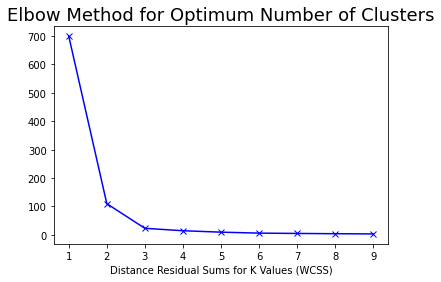

In [19]:
# **5 KMeans Clustering
kmeans = KMeans()
ssd = []
K = range(1, 10)

for k in K:
    kmeans = KMeans(n_clusters=k).fit(gb_s200u)
    ssd.append(kmeans.inertia_)

ssd

plt.plot(K, ssd, "bx-")
plt.xlabel("Distance Residual Sums for K Values (WCSS)")
plt.title("Elbow Method for Optimum Number of Clusters",fontsize=18)
plt.show()

For n_clusters = 2 The average silhouette_score is : 0.7779978024031544
For n_clusters = 3 The average silhouette_score is : 0.8003316706066844
For n_clusters = 4 The average silhouette_score is : 0.6114228733854571
For n_clusters = 5 The average silhouette_score is : 0.5851864465496658
For n_clusters = 6 The average silhouette_score is : 0.5898025696134908


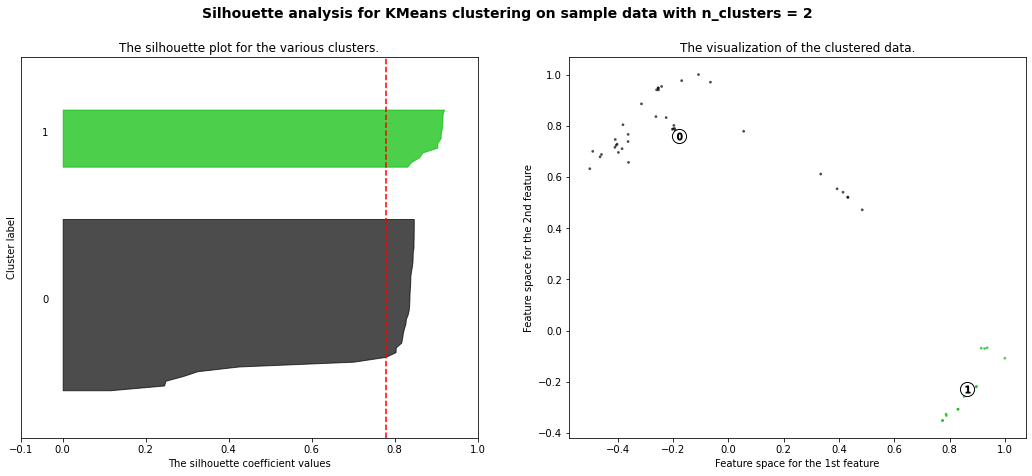

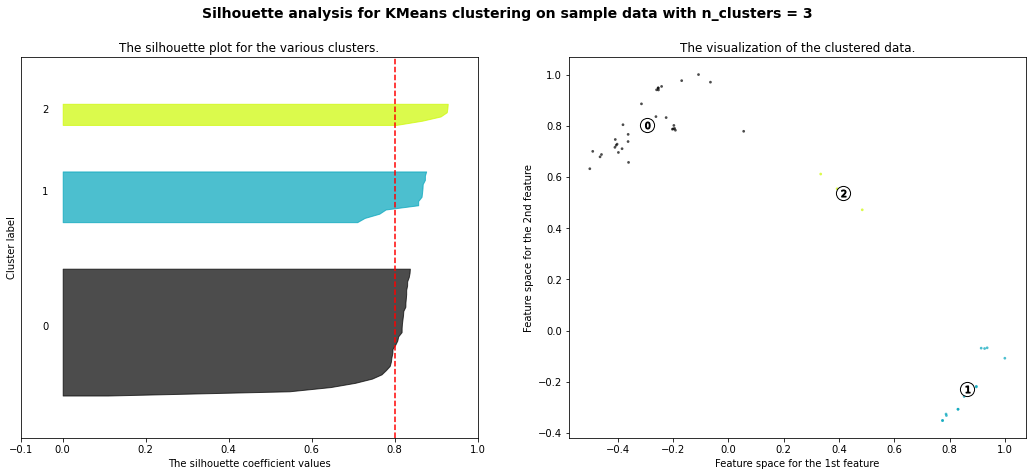

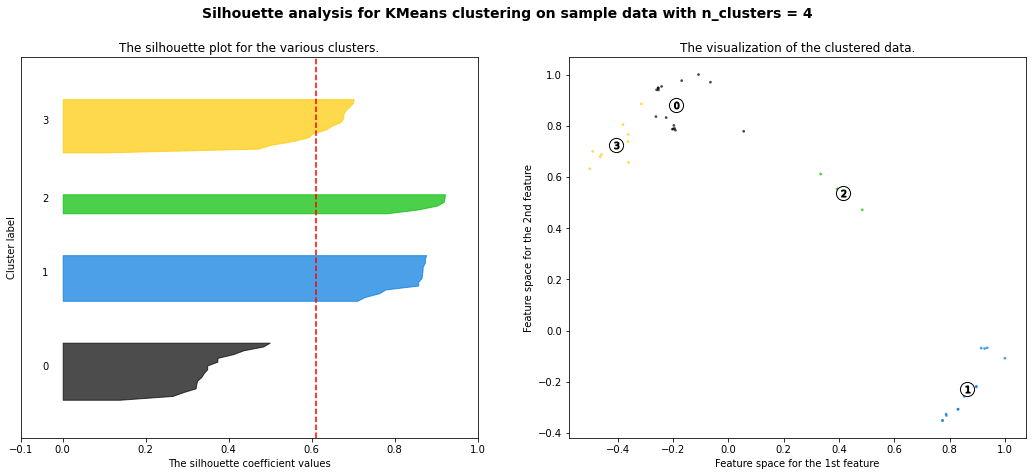

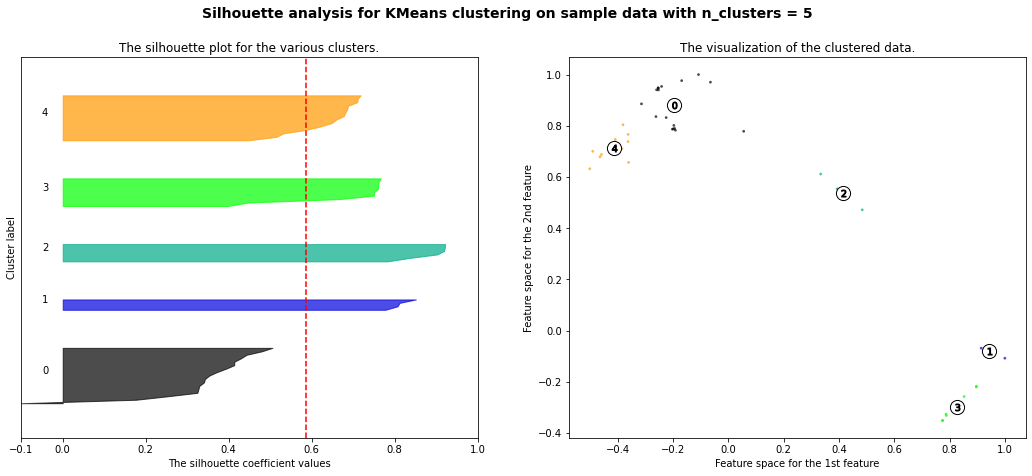

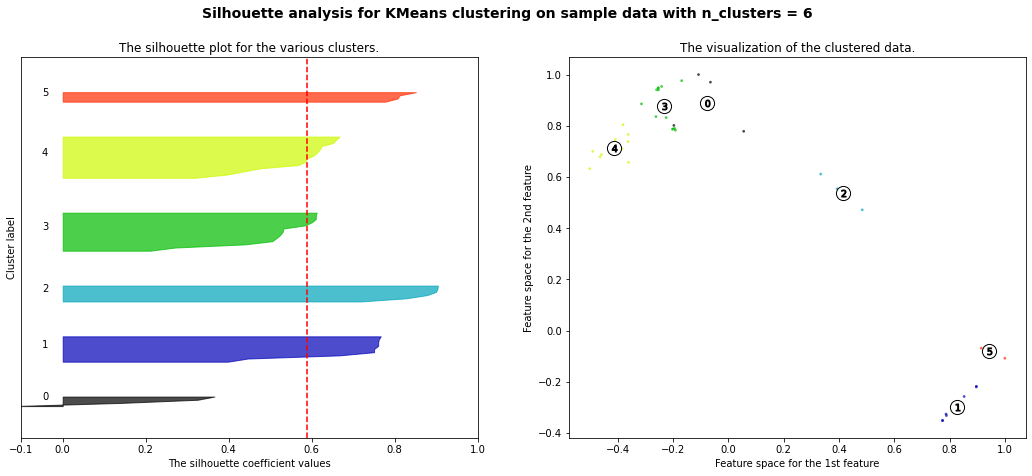

In [20]:
from sklearn.datasets import make_blobs
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_samples, silhouette_score

import matplotlib.pyplot as plt
import matplotlib.cm as cm
import numpy as np

X=np.array(gb_s200u)

len(X)

# Generating the sample data from make_blobs
# This particular setting has one distinct cluster and 3 clusters placed close
# together.
import matplotlib
import matplotlib.pyplot as plt
range_n_clusters = [2, 3, 4, 5, 6]

for n_clusters in range_n_clusters:
    # Create a subplot with 1 row and 2 columns
    fig, (ax1, ax2) = plt.subplots(1, 2)
    fig.set_size_inches(18, 7)

    # The 1st subplot is the silhouette plot
    # The silhouette coefficient can range from -1, 1 but in this example all
    # lie within [-0.1, 1]
    ax1.set_xlim([-0.1, 1])
    # The (n_clusters+1)*10 is for inserting blank space between silhouette
    # plots of individual clusters, to demarcate them clearly.
    ax1.set_ylim([0, len(X) + (n_clusters + 1) * 10])

    # Initialize the clusterer with n_clusters value and a random generator
    # seed of 10 for reproducibility.
    clusterer = KMeans(n_clusters=n_clusters, random_state=10)
    cluster_labels = clusterer.fit_predict(X)

    # The silhouette_score gives the average value for all the samples.
    # This gives a perspective into the density and separation of the formed
    # clusters
    silhouette_avg = silhouette_score(X, cluster_labels)
    print(
        "For n_clusters =",
        n_clusters,
        "The average silhouette_score is :",
        silhouette_avg,
    )

    # Compute the silhouette scores for each sample
    sample_silhouette_values = silhouette_samples(X, cluster_labels)

    y_lower = 10
    for i in range(n_clusters):
        # Aggregate the silhouette scores for samples belonging to
        # cluster i, and sort them
        ith_cluster_silhouette_values = sample_silhouette_values[cluster_labels == i]

        ith_cluster_silhouette_values.sort()

        size_cluster_i = ith_cluster_silhouette_values.shape[0]
        y_upper = y_lower + size_cluster_i

        color = cm.nipy_spectral(float(i) / n_clusters)
        ax1.fill_betweenx(
            np.arange(y_lower, y_upper),
            0,
            ith_cluster_silhouette_values,
            facecolor=color,
            edgecolor=color,
            alpha=0.7,
        )

        # Label the silhouette plots with their cluster numbers at the middle
        ax1.text(-0.05, y_lower + 0.5 * size_cluster_i, str(i))

        # Compute the new y_lower for next plot
        y_lower = y_upper + 10  # 10 for the 0 samples

    ax1.set_title("The silhouette plot for the various clusters.")
    ax1.set_xlabel("The silhouette coefficient values")
    ax1.set_ylabel("Cluster label")

    # The vertical line for average silhouette score of all the values
    ax1.axvline(x=silhouette_avg, color="red", linestyle="--")

    ax1.set_yticks([])  # Clear the yaxis labels / ticks
    ax1.set_xticks([-0.1, 0, 0.2, 0.4, 0.6, 0.8, 1])

    # 2nd Plot showing the actual clusters formed
    colors = matplotlib.cm.nipy_spectral(cluster_labels.astype(float) / n_clusters)
    ax2.scatter(
        X[:, 0], X[:, 1], marker=".", s=30, lw=0, alpha=0.7, c=colors, edgecolor="k"
    )

    # Labeling the clusters
    centers = clusterer.cluster_centers_
    # Draw white circles at cluster centers
    ax2.scatter(
        centers[:, 0],
        centers[:, 1],
        marker="o",
        c="white",
        alpha=1,
        s=200,
        edgecolor="k",
    )

    for i, c in enumerate(centers):
        ax2.scatter(c[0], c[1], marker="$%d$" % i, alpha=1, s=50, edgecolor="k")

    ax2.set_title("The visualization of the clustered data.")
    ax2.set_xlabel("Feature space for the 1st feature")
    ax2.set_ylabel("Feature space for the 2nd feature")

    plt.suptitle(
        "Silhouette analysis for KMeans clustering on sample data with n_clusters = %d"
        % n_clusters,
        fontsize=14,
        fontweight="bold",
    )

plt.show()

In [21]:
from sklearn.metrics import pairwise_distances_argmin_min
#X = np.random.randn(10, 4)
km = KMeans(n_clusters=3).fit(gb_s200u) # spearman
#km = KMeans(n_clusters=4).fit(gb_p200u) # pearson
closest, _ = pairwise_distances_argmin_min(km.cluster_centers_, gb_s200u)
# kmeans medoids features
ft=gb_s200u.iloc[:,closest].columns

print(closest)
print(ft)

[22 30 27]
Index(['wavelet-HLL_glcm_Contrast', 'log-sigma-3-mm-3D_glcm_Idmn',
       'wavelet-LLH_glszm_HighGrayLevelZoneEmphasis'],
      dtype='object')


In [229]:
p1=pd.DataFrame({'U':[10,20],'P':[21,54],"G":[1,2],"U":[10,0]})
p2=pd.DataFrame({'P':[10,20],'U':[21,54]})
p3=pd.DataFrame({'P':[10,20],'G':[21,54],'U':[21,54]})

In [ ]:
if(p1.columns==p2.columns).any():
    print('same')

In [ ]:
p1.columns==p2.columns

In [ ]:
p1.columns

In [ ]:
p2.columns

In [223]:
25+16


41

In [ ]:
p1.columns.intersection(p2.columns)

In [264]:
list(set(p1.columns) & set(p2.columns) & set(p3.columns))

['U', 'P']

In [ ]:
list(set(gb_s200[1].columns) & set(gb_s200[2].columns))

### for N nodes or N_folders

In [44]:
u1=pd.read_csv('D:/gb_NLP_to_paper/gb_nlp_scripts/gb_nlp_scripts/gb_distributed/test/data/maastro/lung1_217_raw.csv')

In [61]:
u2=pd.read_csv('D:/gb_NLP_to_paper/gb_nlp_scripts/gb_nlp_scripts/gb_distributed/test/data/tmh/tmh_217_raw.csv')

In [58]:
u1.iloc[0:100,:]

,original_shape_Maximum2DDiameterColumn,wavelet-HLH_glcm_ClusterProminence,original_shape_Maximum3DDiameter,log-sigma-3-mm-3D_glcm_Idn,original_shape_MajorAxisLength,wavelet-LLH_gldm_SmallDependenceHighGrayLevelEmphasis,original_shape_Maximum2DDiameterRow,wavelet-HLH_glcm_DifferenceVariance,log-sigma-3-mm-3D_ngtdm_Contrast,wavelet-HLH_glrlm_GrayLevelVariance,...,wavelet-HLH_glszm_GrayLevelNonUniformityNormalized,wavelet-LHL_glrlm_RunPercentage,wavelet-LHL_gldm_LargeDependenceEmphasis,log-sigma-3-mm-3D_firstorder_MeanAbsoluteDeviation.1,wavelet-LHH_glrlm_GrayLevelVariance,wavelet-LLH_glcm_JointEnergy,wavelet-HHH_glcm_Contrast,wavelet-LHH_gldm_GrayLevelVariance,wavelet-HHH_glcm_SumSquares,wavelet-HHH_glcm_ClusterTendency
0,94.339811,102903.80510,95.833188,0.952934,84.562987,5392.571450,82.873397,57.002572,0.059098,60.747178,...,0.030680,0.971056,4.216829,65.158992,87.697174,0.002084,39.597502,83.438574,19.356675,37.829198
1,114.769334,60688.41913,124.643492,0.967157,92.495665,4757.036115,102.078401,38.728765,0.029178,37.423644,...,0.038266,0.953540,6.868729,51.036206,45.078119,0.004959,35.524059,41.228937,17.198919,33.271619
2,55.317267,342958.74750,84.970583,0.931439,74.233328,7796.854744,84.380092,123.926392,0.159702,135.197732,...,0.022915,0.979969,3.040423,87.512935,72.349025,0.000670,136.901868,70.259866,66.248324,128.091428
3,110.724884,63649.89987,117.728501,0.947791,107.187905,3117.016008,110.145359,47.925333,0.061032,50.348338,...,0.034433,0.970623,4.269504,56.824662,43.040472,0.001549,43.271741,40.625161,21.053936,40.944005
4,77.820306,203797.53090,102.800778,0.960098,78.417410,8939.477090,85.603738,71.701937,0.056487,75.608732,...,0.030326,0.972684,3.970687,66.798876,78.976929,0.002229,73.242015,75.007701,35.602882,69.169511
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
95,128.763349,16754.18209,133.835720,0.980528,110.959088,1881.913826,133.701159,17.638387,0.010571,20.010439,...,0.053568,0.955408,6.223543,31.249299,18.933724,0.009341,20.797952,17.483789,10.056040,19.426207
96,16.492422,414255.81380,20.099751,0.863081,15.615534,4856.613148,17.088007,107.812323,1.180201,163.622065,...,0.024803,0.995562,1.394231,159.228309,113.276663,0.003889,86.047700,112.020710,42.155026,82.572403
97,64.776539,133268.28980,95.603347,0.944277,64.222478,18327.087540,95.078915,65.938921,0.095831,71.174215,...,0.030801,0.965693,5.187122,81.289160,63.082999,0.001595,52.169946,59.624942,25.374316,49.327319
98,24.331050,552047.16650,28.982753,0.863739,21.786852,6278.021078,23.409400,148.983073,0.634898,202.859047,...,0.020916,0.986630,2.425693,109.840237,83.889307,0.001937,100.466251,82.546301,48.465242,93.394717


In [66]:
u1.iloc[0:100,:].to_csv('D:/gb_NLP_to_paper/gb_nlp_scripts/gb_nlp_scripts/gb_distributed/test/five/maast1/maast1.csv',index=0)

In [67]:
u1.iloc[100:300,:].to_csv('D:/gb_NLP_to_paper/gb_nlp_scripts/gb_nlp_scripts/gb_distributed/test/five/maast2/maast2.csv',index=0)

In [68]:
u1.iloc[300:,:].to_csv('D:/gb_NLP_to_paper/gb_nlp_scripts/gb_nlp_scripts/gb_distributed/test/five/maast3/maast3.csv',index=0)

In [69]:
u2.iloc[:80,:].to_csv('D:/gb_NLP_to_paper/gb_nlp_scripts/gb_nlp_scripts/gb_distributed/test/five/tmh1/tmh1.csv',index=0)

In [70]:
u2.iloc[80:,:].to_csv('D:/gb_NLP_to_paper/gb_nlp_scripts/gb_nlp_scripts/gb_distributed/test/five/tmh2/tmh2.csv',index=0)

In [90]:
path='D:/gb_NLP_to_paper/gb_nlp_scripts/gb_nlp_scripts/gb_distributed/test/five/'
g=[]
for dirName, subdirList, fileList in os.walk(path):
    g.append(subdirList)
print(len(g[0]))

5


In [91]:
print(g[0])

['maast1', 'maast2', 'maast3', 'tmh1', 'tmh2']


In [384]:
def rankify(X):
    
    N = len(X)
    # Rank Vector
    Rank_X = [None for _ in range(N)]
 
    for i in range(N):
        r = 1
        s = 1
 
        # Count no of smaller elements
        # in 0 to i-1
        for j in range(i):
            if (X[j] < X[i]):
                r += 1
            if (X[j] == X[i]):
                s += 1
 
        # Count no of smaller elements
        # in i+1 to N-1
        for j in range(i+1, N):
            if (X[j] < X[i]):
                r += 1
            if (X[j] == X[i]):
                s += 1
 
        # Use Fractional Rank formula
        # fractional_rank = r + (n-1)/2
        Rank_X[i] = r + (s-1) * 0.5
 
    # Return Rank Vector
    return Rank_X

In [385]:
y=[1.0, 1.0, 2.0, 3.0, 3.0, 4.0, 5.0, 5.0, 5.0]

rankify(y)

[1.5, 1.5, 3.0, 4.5, 4.5, 6.0, 8.0, 8.0, 8.0]

In [386]:
y

[1.0, 1.0, 2.0, 3.0, 3.0, 4.0, 5.0, 5.0, 5.0]

In [388]:
rankify(y)

[1.5, 1.5, 3.0, 4.5, 4.5, 6.0, 8.0, 8.0, 8.0]

In [1]:
import sklearn as sk

sk.__version__

C:\Users\Administrator\AppData\Local\Programs\Python\Python38\lib\site-packages\numpy\_distributor_init.py:30: UserWarning: loaded more than 1 DLL from .libs:
C:\Users\Administrator\AppData\Local\Programs\Python\Python38\lib\site-packages\numpy\.libs\libopenblas.PYQHXLVVQ7VESDPUVUADXEVJOBGHJPAY.gfortran-win_amd64.dll
C:\Users\Administrator\AppData\Local\Programs\Python\Python38\lib\site-packages\numpy\.libs\libopenblas64__v0.3.21-gcc_10_3_0.dll
  warnings.warn("loaded more than 1 DLL from .libs:"


'1.0.2'